# Model Performance Diagnostic & Feature Analysis
## Investigating Low/Negative R² Score

This notebook will:
1. Check data quality and distribution
2. Compare Borough vs Zone features
3. Test baseline models for sanity check
4. Analyze feature importance
5. Recommend next steps

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

## 1. Load and Inspect Cleaned Data

In [2]:
# Load cleaned data
df = pd.read_parquet('clean.parquet')

print("Dataset shape:", df.shape)
print("\nColumn types:")
print(df.dtypes)
print("\nFirst few rows:")
display(df.head())
print("\nBasic statistics:")
display(df.describe())

Dataset shape: (619101, 10)

Column types:
trip_distance      double[pyarrow]
fare_amount        double[pyarrow]
extra              double[pyarrow]
mta_tax            double[pyarrow]
tolls_amount       double[pyarrow]
total_amount       double[pyarrow]
payment_type       double[pyarrow]
dropoff_borough    string[pyarrow]
pickup_borough     string[pyarrow]
trip_duration              float64
dtype: object

First few rows:


,trip_distance,fare_amount,extra,mta_tax,tolls_amount,total_amount,payment_type,dropoff_borough,pickup_borough,trip_duration
41,9.9,54.5,0.0,0.5,0.0,55.3,2.0,Brooklyn,Brooklyn,88.35
42,16.46,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,58.45
43,14.94,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,69.05
44,16.56,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,62.70
45,11.13,54.5,0.0,0.5,0.0,55.3,1.0,Queens,Queens,74.60



Basic statistics:


,trip_distance,fare_amount,extra,mta_tax,tolls_amount,total_amount,payment_type,trip_duration
count,619101.0,619101.0,619101.0,619101.0,619101.0,619101.0,619101.0,619101.000000
mean,4.413143,15.414276,0.393557,0.485515,0.32932,18.950364,1.411957,23.956075
std,338.364584,15.493672,0.673826,0.084174,1.496495,17.008912,0.503835,97.353076
min,0.01,0.01,0.0,0.0,0.0,0.01,1.0,0.016667
25%,1.24,7.0,0.0,0.5,0.0,9.3,1.0,7.500000
50%,2.1,10.5,0.0,0.5,0.0,13.8,1.0,12.233333
75%,4.03,17.0,0.5,0.5,0.0,21.66,2.0,20.100000
max,244152.01,2109.0,7.25,3.55,65.55,2113.55,5.0,1439.850000


## 2. Check Target Variable Distribution

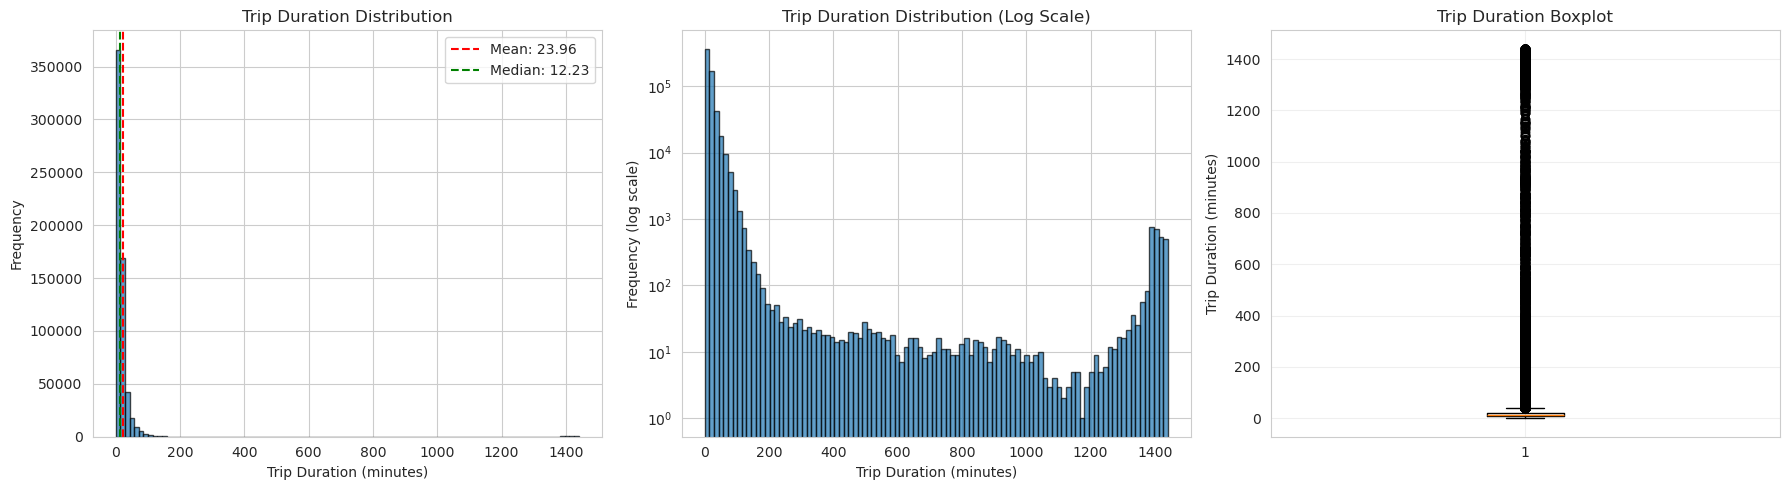


Target Variable Statistics:
Mean: 23.9561
Median: 12.2333
Std: 97.3531
Min: 0.0167
Max: 1439.8500
Skewness: 13.3212
Kurtosis: 182.9088

Percentiles:
0.01      0.750000
0.05      3.350000
0.25      7.500000
0.50     12.233333
0.75     20.100000
0.95     50.766667
0.99    105.250000
Name: trip_duration, dtype: float64


In [3]:
# Check target variable
target = 'trip_duration'

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histogram
axes[0].hist(df[target], bins=100, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Trip Duration (minutes)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Trip Duration Distribution')
axes[0].axvline(df[target].mean(), color='red', linestyle='--', label=f'Mean: {df[target].mean():.2f}')
axes[0].axvline(df[target].median(), color='green', linestyle='--', label=f'Median: {df[target].median():.2f}')
axes[0].legend()

# Log scale histogram
axes[1].hist(df[target], bins=100, edgecolor='black', alpha=0.7)
axes[1].set_xlabel('Trip Duration (minutes)')
axes[1].set_ylabel('Frequency (log scale)')
axes[1].set_title('Trip Duration Distribution (Log Scale)')
axes[1].set_yscale('log')

# Boxplot
axes[2].boxplot(df[target])
axes[2].set_ylabel('Trip Duration (minutes)')
axes[2].set_title('Trip Duration Boxplot')
axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Statistics
print("\nTarget Variable Statistics:")
print(f"Mean: {df[target].mean():.4f}")
print(f"Median: {df[target].median():.4f}")
print(f"Std: {df[target].std():.4f}")
print(f"Min: {df[target].min():.4f}")
print(f"Max: {df[target].max():.4f}")
print(f"Skewness: {df[target].skew():.4f}")
print(f"Kurtosis: {df[target].kurtosis():.4f}")
print(f"\nPercentiles:")
print(df[target].quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]))

## 3. Check for Data Leakage or Outliers

PEARSON CORRELATION ANALYSIS (Linear Relationships)

Pearson correlations with trip_duration:
fare_amount      0.161583
total_amount     0.156394
tolls_amount     0.072151
payment_type     0.019017
extra            0.013833
mta_tax          0.008697
trip_distance    0.001917
Name: trip_duration, dtype: float64

⚠️  Checking for data leakage (|correlation| > 0.95):
✅ No perfect correlations detected (Pearson)

SPEARMAN CORRELATION ANALYSIS (Monotonic Relationships)

Pearson correlations with trip_duration:
fare_amount      0.161583
total_amount     0.156394
tolls_amount     0.072151
payment_type     0.019017
extra            0.013833
mta_tax          0.008697
trip_distance    0.001917
Name: trip_duration, dtype: float64

⚠️  Checking for data leakage (|correlation| > 0.95):
✅ No perfect correlations detected (Pearson)

SPEARMAN CORRELATION ANALYSIS (Monotonic Relationships)

Spearman correlations with trip_duration:
fare_amount      0.931578
total_amount     0.887036
trip_distance    0.

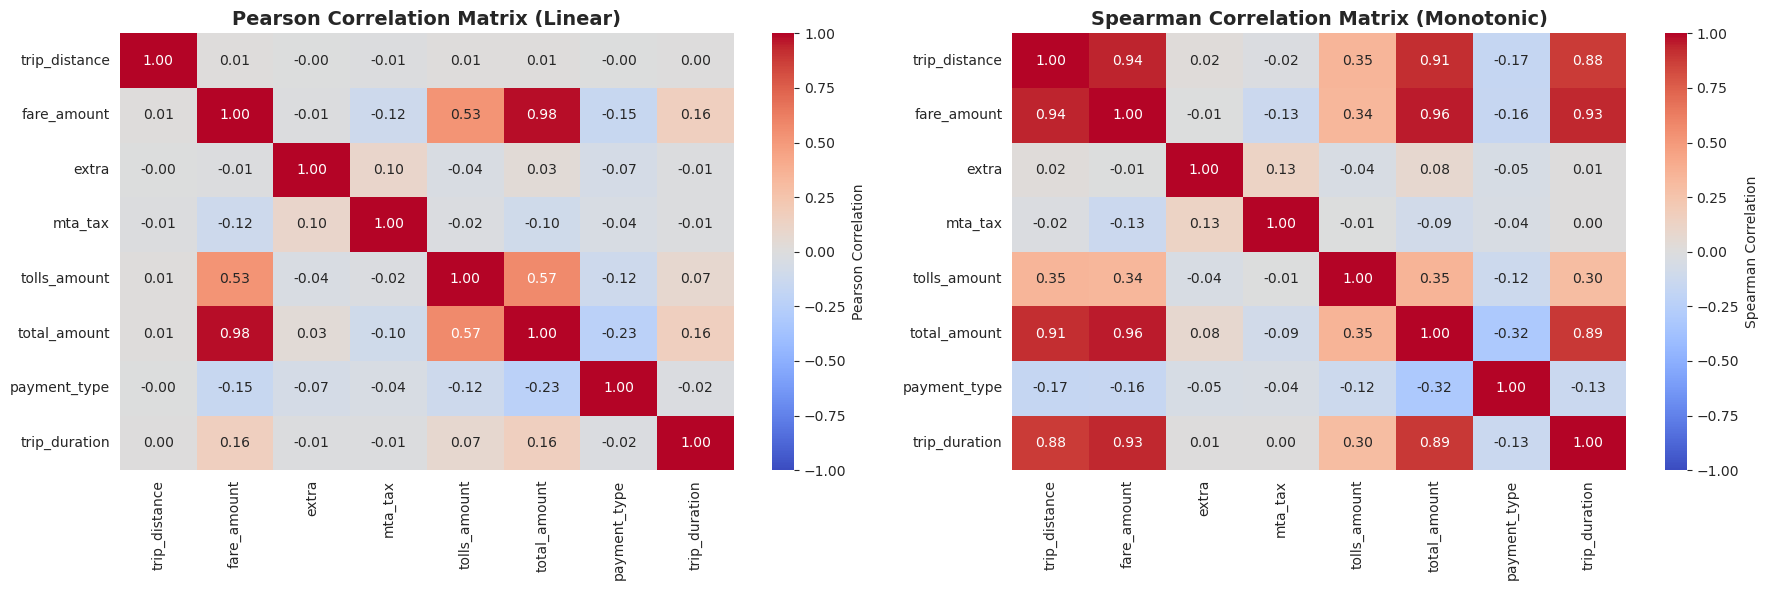


PEARSON vs SPEARMAN COMPARISON

Top features by Spearman correlation:


,Feature,Pearson,Spearman,Difference
0,fare_amount,0.161583,0.931578,0.769995
1,total_amount,0.156394,0.887036,0.730642
6,trip_distance,0.001917,0.875894,0.873977
2,tolls_amount,0.072151,0.300376,0.228225
3,payment_type,0.019017,0.134377,0.115360
4,extra,0.013833,0.006716,-0.007117
5,mta_tax,0.008697,0.003162,-0.005535



📊 INTERPRETATION:
   - Large Pearson correlation: Strong LINEAR relationship
   - Large Spearman correlation: Strong MONOTONIC relationship
   - Spearman >> Pearson: NON-LINEAR monotonic relationship (neural networks can help)
   - Spearman ≈ Pearson: Linear relationship (simple models sufficient)

✅ 4 features show strong NON-LINEAR relationships:
   - fare_amount: Pearson=0.162, Spearman=0.932
   - total_amount: Pearson=0.156, Spearman=0.887
   - trip_distance: Pearson=0.002, Spearman=0.876
   - tolls_amount: Pearson=0.072, Spearman=0.300
   → Neural networks or tree-based models recommended!

OUTLIER DETECTION
⚠️  trip_distance: 32,845 outliers (5.31%)
⚠️  fare_amount: 30,874 outliers (4.99%)
⚠️  extra: 24,497 outliers (3.96%)
⚠️  mta_tax: 17,957 outliers (2.90%)
⚠️  tolls_amount: 31,199 outliers (5.04%)
⚠️  total_amount: 25,433 outliers (4.11%)
✅ payment_type: 0 outliers (0.00%)
⚠️  trip_duration: 23,827 outliers (3.85%)


In [6]:
# Check for perfect correlations that might indicate data leakage
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()

# Pearson correlation (linear relationships)
print("="*80)
print("PEARSON CORRELATION ANALYSIS (Linear Relationships)")
print("="*80)
corr_pearson = df[numeric_cols].corr(method='pearson')

# Find high correlations with target
target_corr_pearson = corr_pearson[target].drop(target).abs().sort_values(ascending=False)
print(f"\nPearson correlations with {target}:")
print(target_corr_pearson)

# Check for suspiciously high correlations (potential leakage)
print("\n⚠️  Checking for data leakage (|correlation| > 0.95):")
high_corr_pearson = target_corr_pearson[target_corr_pearson > 0.95]
if len(high_corr_pearson) > 0:
    print("❌ POTENTIAL LEAKAGE DETECTED:")
    for col, corr in high_corr_pearson.items():
        print(f"   - {col}: {corr:.4f}")
else:
    print("✅ No perfect correlations detected (Pearson)")

# Spearman correlation (monotonic relationships)
print("\n" + "="*80)
print("SPEARMAN CORRELATION ANALYSIS (Monotonic Relationships)")
print("="*80)
corr_spearman = df[numeric_cols].corr(method='spearman')

# Find high correlations with target
target_corr_spearman = corr_spearman[target].drop(target).abs().sort_values(ascending=False)
print(f"\nSpearman correlations with {target}:")
print(target_corr_spearman)

# Check for suspiciously high correlations (potential leakage)
print("\n⚠️  Checking for data leakage (|correlation| > 0.95):")
high_corr_spearman = target_corr_spearman[target_corr_spearman > 0.95]
if len(high_corr_spearman) > 0:
    print("❌ POTENTIAL LEAKAGE DETECTED:")
    for col, corr in high_corr_spearman.items():
        print(f"   - {col}: {corr:.4f}")
else:
    print("✅ No perfect correlations detected (Spearman)")

# Visualize both correlation types
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

# Pearson
sns.heatmap(corr_pearson, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, vmin=-1, vmax=1, ax=axes[0], cbar_kws={'label': 'Pearson Correlation'})
axes[0].set_title('Pearson Correlation Matrix (Linear)', fontsize=14, fontweight='bold')

# Spearman
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', 
            center=0, vmin=-1, vmax=1, ax=axes[1], cbar_kws={'label': 'Spearman Correlation'})
axes[1].set_title('Spearman Correlation Matrix (Monotonic)', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

# Compare Pearson vs Spearman
print("\n" + "="*80)
print("PEARSON vs SPEARMAN COMPARISON")
print("="*80)
comparison = pd.DataFrame({
    'Feature': target_corr_pearson.index,
    'Pearson': target_corr_pearson.values,
    'Spearman': target_corr_spearman.loc[target_corr_pearson.index].values,
    'Difference': target_corr_spearman.loc[target_corr_pearson.index].values - target_corr_pearson.values
}).sort_values('Spearman', ascending=False)

print("\nTop features by Spearman correlation:")
display(comparison)

print("\n📊 INTERPRETATION:")
print("   - Large Pearson correlation: Strong LINEAR relationship")
print("   - Large Spearman correlation: Strong MONOTONIC relationship")
print("   - Spearman >> Pearson: NON-LINEAR monotonic relationship (neural networks can help)")
print("   - Spearman ≈ Pearson: Linear relationship (simple models sufficient)")

# Flag non-linear features
comparison['Non_Linear'] = comparison['Difference'].abs() > 0.2
non_linear_features = comparison[comparison['Non_Linear']]
if len(non_linear_features) > 0:
    print(f"\n✅ {len(non_linear_features)} features show strong NON-LINEAR relationships:")
    for idx, row in non_linear_features.iterrows():
        print(f"   - {row['Feature']}: Pearson={row['Pearson']:.3f}, Spearman={row['Spearman']:.3f}")
    print("   → Neural networks or tree-based models recommended!")
else:
    print("\n⚠️  No strong non-linear relationships detected.")
    print("   → Linear models may be sufficient.")

# Check for outliers
print("\n" + "="*80)
print("OUTLIER DETECTION")
print("="*80)
for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 3 * iqr
    upper_bound = q3 + 3 * iqr
    outliers = ((df[col] < lower_bound) | (df[col] > upper_bound)).sum()
    outlier_pct = (outliers / len(df)) * 100
    
    if outlier_pct > 1:
        print(f"⚠️  {col}: {outliers:,} outliers ({outlier_pct:.2f}%)")
    else:
        print(f"✅ {col}: {outliers:,} outliers ({outlier_pct:.2f}%)")


## 4. Test Simple Baseline Models

In [7]:
# Prepare data
y = df[target].values
X = df.drop(target, axis=1)

# Get dummies
categorical_cols = X.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
print(f"Categorical columns: {categorical_cols}")

if len(categorical_cols) > 0:
    X_encoded = pd.get_dummies(X, columns=categorical_cols, drop_first=True)
else:
    X_encoded = X.copy()

print(f"\nFeature matrix shape: {X_encoded.shape}")
print(f"Number of features: {X_encoded.shape[1]}")

# Split data
X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)

print(f"\nTrain set size: {len(X_train)}")
print(f"Test set size: {len(X_test)}")

Categorical columns: ['dropoff_borough', 'pickup_borough']

Feature matrix shape: (619101, 19)
Number of features: 19

Train set size: 495280
Test set size: 123821


In [8]:
# Baseline 1: Mean Prediction (worst case)
y_pred_mean = np.full_like(y_test, y_train.mean())
r2_mean = r2_score(y_test, y_pred_mean)
rmse_mean = np.sqrt(mean_squared_error(y_test, y_pred_mean))
mae_mean = mean_absolute_error(y_test, y_pred_mean)

print("="*60)
print("BASELINE 1: Mean Prediction (Should give R² = 0)")
print("="*60)
print(f"R²:   {r2_mean:.4f}")
print(f"RMSE: {rmse_mean:.4f}")
print(f"MAE:  {mae_mean:.4f}")
print()

# Baseline 2: Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
y_pred_lr = lr_model.predict(X_test)
r2_lr = r2_score(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
mae_lr = mean_absolute_error(y_test, y_pred_lr)

print("="*60)
print("BASELINE 2: Linear Regression")
print("="*60)
print(f"R²:   {r2_lr:.4f}")
print(f"RMSE: {rmse_lr:.4f}")
print(f"MAE:  {mae_lr:.4f}")
print()

# Baseline 3: Random Forest (should work well)
rf_model = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)
y_pred_rf = rf_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
mae_rf = mean_absolute_error(y_test, y_pred_rf)

print("="*60)
print("BASELINE 3: Random Forest")
print("="*60)
print(f"R²:   {r2_rf:.4f}")
print(f"RMSE: {rmse_rf:.4f}")
print(f"MAE:  {mae_rf:.4f}")
print()

print("\n" + "="*60)
print("DIAGNOSIS:")
print("="*60)
if r2_lr < 0 and r2_rf < 0:
    print("❌ CRITICAL: Both Linear Regression and Random Forest have negative R²")
    print("   This indicates a SEVERE data quality or preprocessing issue.")
    print("   Possible causes:")
    print("   1. Target variable is incorrectly defined or scaled")
    print("   2. Features and target don't match (shuffled indices)")
    print("   3. Data leakage in reverse (test data contaminating training)")
elif r2_lr > 0 and r2_rf > 0.5:
    print("✅ Good: Baseline models work. Neural network needs tuning.")
    print("   Your neural network architecture or training process needs adjustment.")
elif r2_lr < 0 and r2_rf > 0:
    print("⚠️  Linear model fails but tree model works.")
    print("   Data has strong non-linear relationships (expected for taxi data).")
    print("   Neural network should work with proper configuration.")
else:
    print("⚠️  Mixed results. Further investigation needed.")

BASELINE 1: Mean Prediction (Should give R² = 0)
R²:   -0.0000
RMSE: 97.7660
MAE:  21.0869

BASELINE 2: Linear Regression
R²:   0.0263
RMSE: 96.4710
MAE:  15.1831

BASELINE 3: Random Forest
R²:   0.0308
RMSE: 96.2475
MAE:  14.4687


DIAGNOSIS:
⚠️  Mixed results. Further investigation needed.


## 5. Feature Importance Analysis


Top 20 Most Important Features:
                          feature    importance
1                     fare_amount  4.140934e-01
0                   trip_distance  2.744344e-01
5                    total_amount  1.619148e-01
6                    payment_type  2.187806e-02
2                           extra  2.021736e-02
3                         mta_tax  1.676164e-02
10         dropoff_borough_Queens  1.606140e-02
15       pickup_borough_Manhattan  1.345917e-02
16          pickup_borough_Queens  1.304489e-02
13        pickup_borough_Brooklyn  1.237308e-02
7        dropoff_borough_Brooklyn  1.061206e-02
4                    tolls_amount  9.371459e-03
9       dropoff_borough_Manhattan  9.042690e-03
12        dropoff_borough_Unknown  4.226072e-03
17   pickup_borough_Staten Island  1.111999e-03
11  dropoff_borough_Staten Island  9.172273e-04
8             dropoff_borough_EWR  3.996194e-04
18         pickup_borough_Unknown  8.067883e-05
14             pickup_borough_EWR  1.831338e-08


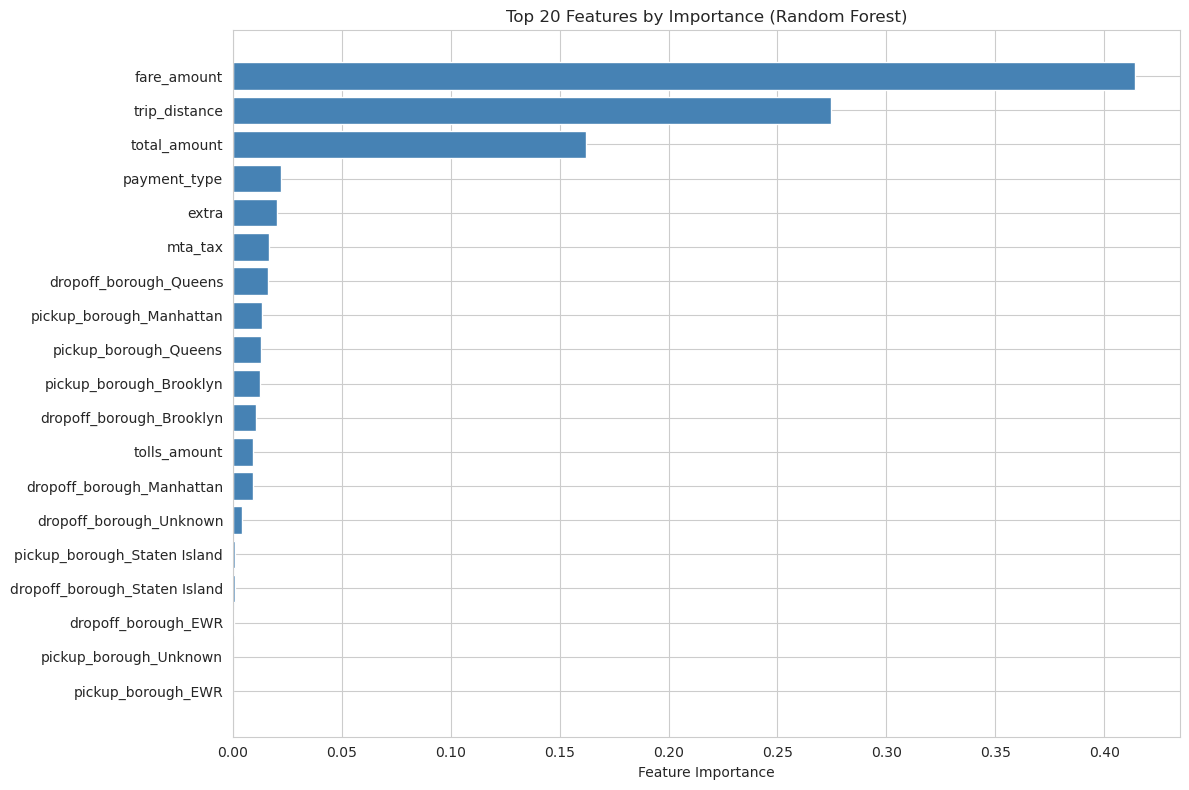

In [9]:
# Get feature importance from Random Forest
feature_importance = pd.DataFrame({
    'feature': X_encoded.columns,
    'importance': rf_model.feature_importances_
}).sort_values('importance', ascending=False)

print("\nTop 20 Most Important Features:")
print(feature_importance.head(20))

# Visualize
plt.figure(figsize=(12, 8))
top_features = feature_importance.head(20)
plt.barh(range(len(top_features)), top_features['importance'], color='steelblue')
plt.yticks(range(len(top_features)), top_features['feature'])
plt.xlabel('Feature Importance')
plt.title('Top 20 Features by Importance (Random Forest)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 6. Compare Borough vs Zone Features

Let's compare model performance with Borough (current) vs Zone (detailed location) features.

In [10]:
# Load original data with zones
print("Loading original data with zone information...")
df_original = pd.read_csv('bq-results-20251021-151536-1761059869369.csv', dtype_backend='pyarrow')
df_original.drop(columns=['data_file_year','data_file_month'], inplace=True)

# Load taxi zone lookup
taxi_zone_lookup_df = pd.read_csv('taxi_zone_lookup.csv', dtype_backend='pyarrow')

# Merge zones (NOT boroughs)
df_with_zones = df_original.copy()
df_with_zones = df_with_zones.merge(taxi_zone_lookup_df[['LocationID', 'Zone']], 
                                      left_on='dropoff_location_id', right_on='LocationID', how='left')
df_with_zones.rename(columns={'Zone': 'dropoff_zone'}, inplace=True)
df_with_zones.drop(columns=['LocationID'], inplace=True)

df_with_zones = df_with_zones.merge(taxi_zone_lookup_df[['LocationID', 'Zone']], 
                                     left_on='pickup_location_id', right_on='LocationID', how='left')
df_with_zones.rename(columns={'Zone': 'pickup_zone'}, inplace=True)
df_with_zones.drop(columns=['LocationID', 'dropoff_location_id', 'pickup_location_id'], inplace=True)

# Apply same cleaning steps
df_with_zones = df_with_zones.dropna(axis=1, how='all')
df_with_zones['pickup_datetime'] = pd.to_datetime(df_with_zones['pickup_datetime'])
df_with_zones['dropoff_datetime'] = pd.to_datetime(df_with_zones['dropoff_datetime'])
df_with_zones['trip_duration'] = (df_with_zones['dropoff_datetime'] - df_with_zones['pickup_datetime']).dt.total_seconds() / 60
df_with_zones.drop(columns=['dropoff_datetime'], inplace=True)

# Apply validation rules (same as clean.parquet)
df_with_zones = df_with_zones[df_with_zones['trip_duration'] > 0]
df_with_zones = df_with_zones[df_with_zones['trip_distance'] > 0]
df_with_zones = df_with_zones[df_with_zones['total_amount'] > 0]
df_with_zones = df_with_zones[df_with_zones['fare_amount'] > 0]
df_with_zones = df_with_zones[(df_with_zones['payment_type'] >= 1) & (df_with_zones['payment_type'] <= 6)]

# Drop same columns as clean.parquet
cols_to_drop = ['vendor_id', 'pickup_datetime', 'rate_code', 'passenger_count', 
                'tip_amount', 'trip_type', 'imp_surcharge', 'store_and_fwd_flag']
df_with_zones.drop(columns=[c for c in cols_to_drop if c in df_with_zones.columns], inplace=True)

print(f"\nDataset with zones shape: {df_with_zones.shape}")
print(f"Unique pickup zones: {df_with_zones['pickup_zone'].nunique()}")
print(f"Unique dropoff zones: {df_with_zones['dropoff_zone'].nunique()}")

Loading original data with zone information...

Dataset with zones shape: (619101, 10)
Unique pickup zones: 235
Unique dropoff zones: 258


In [11]:
# Prepare zone-based features
y_zones = df_with_zones['trip_duration'].values
X_zones = df_with_zones.drop('trip_duration', axis=1)

categorical_cols_zones = X_zones.select_dtypes(include=['object', 'category', 'string']).columns.tolist()
print(f"Categorical columns with zones: {categorical_cols_zones}")

if len(categorical_cols_zones) > 0:
    X_zones_encoded = pd.get_dummies(X_zones, columns=categorical_cols_zones, drop_first=True)
else:
    X_zones_encoded = X_zones.copy()

print(f"\nFeature matrix shape WITH ZONES: {X_zones_encoded.shape}")
print(f"Number of features WITH ZONES: {X_zones_encoded.shape[1]}")

# Split
X_train_z, X_test_z, y_train_z, y_test_z = train_test_split(
    X_zones_encoded, y_zones, test_size=0.2, random_state=42
)

Categorical columns with zones: ['dropoff_zone', 'pickup_zone']

Feature matrix shape WITH ZONES: (619101, 498)
Number of features WITH ZONES: 498


In [ ]:
# Test Random Forest with zones
print("Training Random Forest with ZONE features...")
rf_zones = RandomForestRegressor(n_estimators=50, max_depth=10, random_state=42, n_jobs=-1)
rf_zones.fit(X_train_z, y_train_z)
y_pred_zones = rf_zones.predict(X_test_z)

r2_zones = r2_score(y_test_z, y_pred_zones)
rmse_zones = np.sqrt(mean_squared_error(y_test_z, y_pred_zones))
mae_zones = mean_absolute_error(y_test_z, y_pred_zones)

print("\n" + "="*80)
print("COMPARISON: Borough vs Zone Features")
print("="*80)
print(f"\n{'Metric':<20} {'Borough (Current)':<25} {'Zone (Detailed)':<25} {'Improvement'}")
print("-"*80)
print(f"{'R² Score':<20} {r2_rf:<25.4f} {r2_zones:<25.4f} {((r2_zones - r2_rf) / abs(r2_rf) * 100 if r2_rf != 0 else 0):>10.1f}%")
print(f"{'RMSE':<20} {rmse_rf:<25.4f} {rmse_zones:<25.4f} {((rmse_rf - rmse_zones) / rmse_rf * 100):>10.1f}%")
print(f"{'MAE':<20} {mae_rf:<25.4f} {mae_zones:<25.4f} {((mae_rf - mae_zones) / mae_rf * 100):>10.1f}%")
print(f"{'# Features':<20} {X_encoded.shape[1]:<25} {X_zones_encoded.shape[1]:<25}")
print("="*80)

improvement = ((r2_zones - r2_rf) / abs(r2_rf) * 100) if r2_rf != 0 else 0
if improvement > 20:
    print("\n✅ RECOMMENDATION: Use ZONE features! Significant improvement detected.")
    print(f"   R² improved by {improvement:.1f}%")
    print("   The granular location information is valuable for trip duration prediction.")
elif improvement > 5:
    print("\n⚠️  RECOMMENDATION: Consider using ZONE features.")
    print(f"   R² improved by {improvement:.1f}%, but comes with {X_zones_encoded.shape[1]} features.")
    print("   Trade-off between accuracy and model complexity.")
else:
    print("\n📊 RECOMMENDATION: Borough features are sufficient.")
    print(f"   Only {improvement:.1f}% improvement with {X_zones_encoded.shape[1] - X_encoded.shape[1]} extra features.")
    print("   Not worth the added complexity.")

Training Random Forest with ZONE features...


## 7. Neural Network Sanity Check

Let's test a **simple** neural network to see if the issue is with the architecture.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Scale data
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert to tensors (keep on CPU for DataLoader)
X_train_t = torch.FloatTensor(X_train_scaled)
y_train_t = torch.FloatTensor(y_train).unsqueeze(1)
X_test_t = torch.FloatTensor(X_test_scaled).to(device)
y_test_t = torch.FloatTensor(y_test).unsqueeze(1).to(device)

# Create DataLoader
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, pin_memory=True if device.type == 'cuda' else False)

print(f"\nTrain tensor shape: {X_train_t.shape}")
print(f"Test tensor shape: {X_test_t.shape}")

In [ ]:
# Define SIMPLE neural network (no attention, just 2 layers)
class SimpleNN(nn.Module):
    def __init__(self, input_dim):
        super(SimpleNN, self).__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.BatchNorm1d(128),
            nn.Dropout(0.2),
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.BatchNorm1d(64),
            nn.Dropout(0.1),
            
            nn.Linear(64, 1)
        )
    
    def forward(self, x):
        return self.network(x)

# Train
model = SimpleNN(X_train_scaled.shape[1]).to(device)
criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Training simple neural network...")
epochs = 100
model.train()

for epoch in range(epochs):
    epoch_loss = 0
    for batch_X, batch_y in train_loader:
        batch_X = batch_X.to(device)
        batch_y = batch_y.to(device)
        
        optimizer.zero_grad()
        outputs = model(batch_X)
        loss = criterion(outputs, batch_y)
        loss.backward()
        optimizer.step()
        
        epoch_loss += loss.item()
    
    if (epoch + 1) % 20 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {epoch_loss/len(train_loader):.4f}")

# Evaluate
model.eval()
with torch.no_grad():
    y_pred_nn = model(X_test_t).squeeze().cpu().numpy()

r2_nn = r2_score(y_test, y_pred_nn)
rmse_nn = np.sqrt(mean_squared_error(y_test, y_pred_nn))
mae_nn = mean_absolute_error(y_test, y_pred_nn)

print("\n" + "="*60)
print("SIMPLE NEURAL NETWORK RESULTS")
print("="*60)
print(f"R²:   {r2_nn:.4f}")
print(f"RMSE: {rmse_nn:.4f}")
print(f"MAE:  {mae_nn:.4f}")
print("="*60)

if r2_nn < 0:
    print("\n❌ CRITICAL: Even simple neural network fails!")
    print("   This is NOT an architecture issue.")
    print("   Check:")
    print("   1. Data preprocessing (scaling, encoding)")
    print("   2. Target variable definition")
    print("   3. Train/test split consistency")
elif r2_nn > 0.5:
    print("\n✅ Simple network works! Your complex architecture has issues.")
    print("   Problem likely with:")
    print("   1. Attention mechanism")
    print("   2. Too deep architecture (overfitting/underfitting)")
    print("   3. Learning rate too high/low")
    print("   4. Dropout rates too aggressive")
else:
    print("\n⚠️  Simple network has low but positive R².")
    print("   Neural networks may not be ideal for this dataset.")
    print("   Tree-based models (Random Forest, XGBoost) likely better choice.")

## 8. Summary and Recommendations

In [ ]:
# Create summary comparison
summary = pd.DataFrame([
    {'Model': 'Mean Baseline', 'R²': r2_mean, 'RMSE': rmse_mean, 'MAE': mae_mean},
    {'Model': 'Linear Regression', 'R²': r2_lr, 'RMSE': rmse_lr, 'MAE': mae_lr},
    {'Model': 'Random Forest (Borough)', 'R²': r2_rf, 'RMSE': rmse_rf, 'MAE': mae_rf},
    {'Model': 'Random Forest (Zone)', 'R²': r2_zones, 'RMSE': rmse_zones, 'MAE': mae_zones},
    {'Model': 'Simple Neural Network', 'R²': r2_nn, 'RMSE': rmse_nn, 'MAE': mae_nn},
]).sort_values('R²', ascending=False)

print("\n" + "="*80)
print("FINAL MODEL COMPARISON")
print("="*80)
display(summary)

# Visualization
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].barh(summary['Model'], summary['R²'], color='steelblue', alpha=0.7)
axes[0].set_xlabel('R² Score (higher is better)')
axes[0].set_title('Model Comparison: R²')
axes[0].axvline(x=0, color='red', linestyle='--', linewidth=2)
axes[0].grid(True, alpha=0.3, axis='x')

axes[1].barh(summary['Model'], summary['RMSE'], color='coral', alpha=0.7)
axes[1].set_xlabel('RMSE (lower is better)')
axes[1].set_title('Model Comparison: RMSE')
axes[1].grid(True, alpha=0.3, axis='x')

axes[2].barh(summary['Model'], summary['MAE'], color='seagreen', alpha=0.7)
axes[2].set_xlabel('MAE (lower is better)')
axes[2].set_title('Model Comparison: MAE')
axes[2].grid(True, alpha=0.3, axis='x')

plt.tight_layout()
plt.savefig('model_diagnostic_summary.png', dpi=300, bbox_inches='tight')
plt.show()

print("\nVisualization saved to 'model_diagnostic_summary.png'")

In [ ]:
print("\n" + "="*80)
print("FINAL RECOMMENDATIONS")
print("="*80)

best_model = summary.iloc[0]
print(f"\n🏆 Best performing model: {best_model['Model']} (R² = {best_model['R²']:.4f})")

if r2_zones > r2_rf * 1.2:  # 20% improvement
    print("\n✅ Use ZONE features instead of Borough:")
    print(f"   - Improvement: {((r2_zones - r2_rf) / abs(r2_rf) * 100):.1f}%")
    print(f"   - Features: {X_zones_encoded.shape[1]} (vs {X_encoded.shape[1]} with Borough)")
    print("   - Recommended: Train deeper network or use feature selection")

if r2_nn < 0:
    print("\n❌ Neural Network Issues Detected:")
    print("   1. Check data preprocessing in initial_match.ipynb")
    print("   2. Verify target variable is correctly loaded")
    print("   3. Check for train/test data mismatch")
    print("   4. Simplify architecture (remove attention mechanism)")
    print("   5. Reduce learning rate to 0.0001")
    print("   6. Reduce dropout rates")
elif r2_nn > 0 and r2_nn < r2_rf * 0.8:  # NN performs worse than RF
    print("\n⚠️  Neural Network underperforming:")
    print("   - Consider using tree-based models (Random Forest, XGBoost) instead")
    print("   - Or simplify NN architecture and increase training epochs")
    print("   - Taxi trip data may not benefit from deep learning complexity")
else:
    print("\n✅ Neural Network can work for this data:")
    print("   - Remove or simplify attention mechanism")
    print("   - Use 3-4 layers instead of 6")
    print("   - Reduce dropout (use 0.1-0.2 max)")
    print("   - Lower learning rate to 0.0001-0.0005")
    print("   - Train for more epochs (500-1000)")

print("\n" + "="*80)